<a href="https://colab.research.google.com/github/rajmatondkar3-eng/CSL701-CS30_Machine-Learning-Lab/blob/main/ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : Raj Shriram Matondkar

Batch : CS-2


Roll Number : CS-30



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:
# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Upload the dataset in Google Colab
from google.colab import files
uploaded = files.upload()

# Read the CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Display the dataset
print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Saving Mall_Customers.csv to Mall_Customers.csv
First five rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset shape: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:
# Select the required features
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Handle missing values if present
X = X.dropna()

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Selected features:")
print(X.head())

print("\nFirst five standardized records:")
print(X_scaled[:5])

print("\nStandardized feature means:")
print(X_scaled.mean(axis=0))

print("\nStandardized feature standard deviations:")
print(X_scaled.std(axis=0))

Selected features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

First five standardized records:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]

Standardized feature means:
[-2.13162821e-16 -1.46549439e-16]

Standardized feature standard deviations:
[1. 1.]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

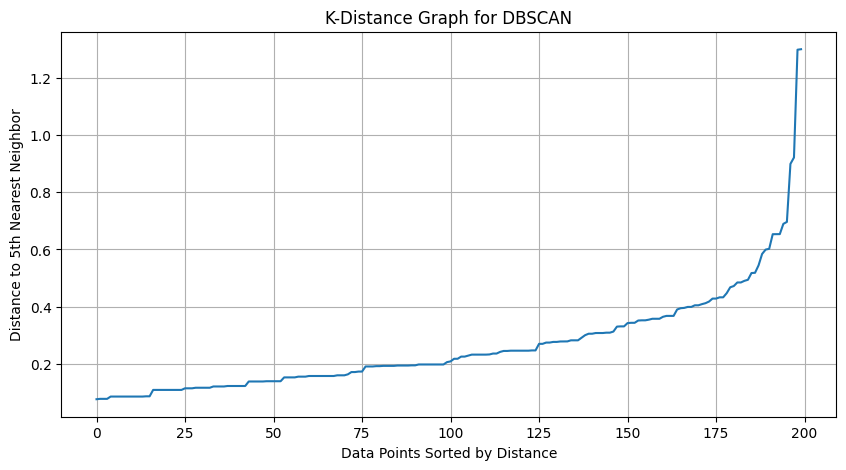

Initial min_samples: 5
Initial eps: 0.35


In [ ]:
# Set min_samples
min_samples = 5

# Compute nearest neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Extract and sort k-distances
k_distances = np.sort(distances[:, min_samples - 1])

# Plot the k-distance graph
plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.xlabel("Data Points Sorted by Distance")
plt.ylabel(f"Distance to {min_samples}th Nearest Neighbor")
plt.title("K-Distance Graph for DBSCAN")
plt.grid(True)
plt.show()

# Choose epsilon by inspecting the elbow in the graph
eps = 0.35

print("Initial min_samples:", min_samples)
print("Initial eps:", eps)

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

Cluster labels:
[-1  0  1  2  3  4  5]

First five clustered records:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster  
0        2  
1        0  
2        1  
3        0  
4        2  


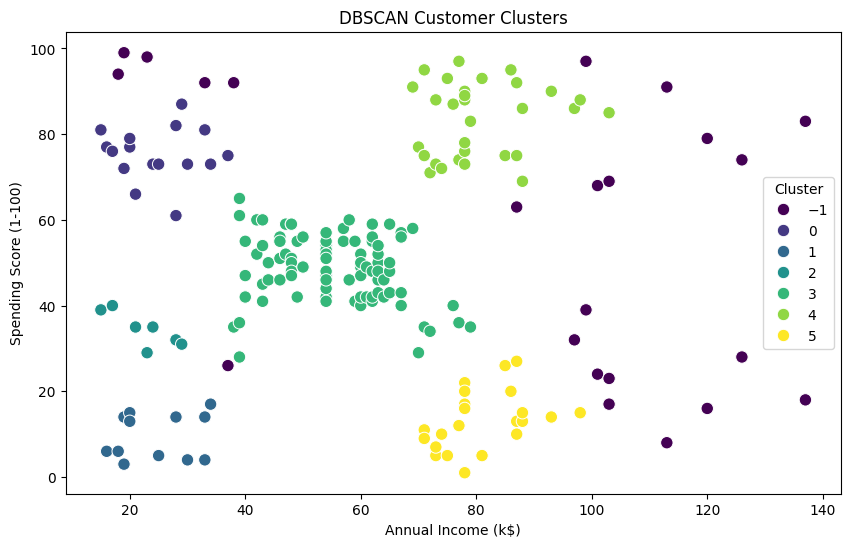

In [ ]:
# Create the DBSCAN model
dbscan = DBSCAN(
    eps=eps,
    min_samples=min_samples
)

# Fit the model and generate cluster labels
labels = dbscan.fit_predict(X_scaled)

# Add cluster labels to the dataset rows used for clustering
clustered_df = df.loc[X.index].copy()
clustered_df["Cluster"] = labels

print("Cluster labels:")
print(np.unique(labels))

print("\nFirst five clustered records:")
print(clustered_df.head())

# Visualize the clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X["Annual Income (k$)"],
    y=X["Spending Score (1-100)"],
    hue=labels,
    palette="viridis",
    s=80
)

plt.title("DBSCAN Customer Clusters")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

Number of clusters: 6
Number of noise points: 23
Percentage of noise points: 11.5 %
Silhouette Score (excluding noise): 0.5577

Points in each cluster:
-1    23
 0    16
 1    12
 2     7
 3    88
 4    31
 5    23
Name: count, dtype: int64


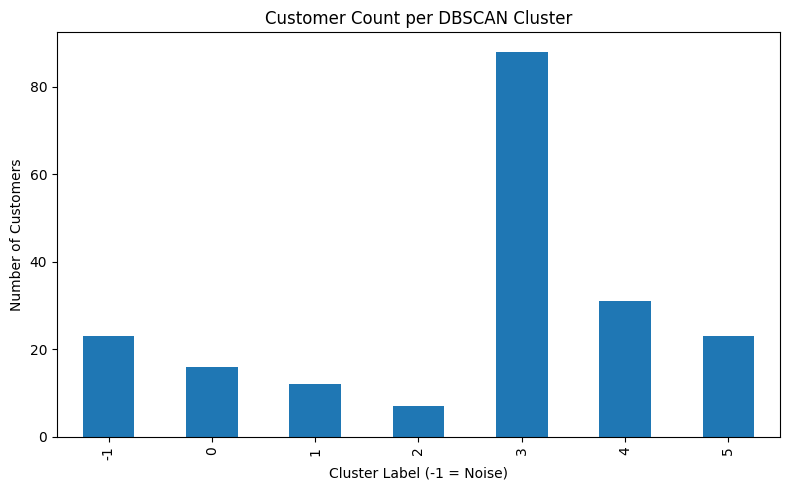

In [ ]:
# Count clusters, excluding noise label -1
unique_labels = set(labels)
n_clusters = len(unique_labels - {-1})

# Count noise points
n_noise = np.sum(labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Percentage of noise points:",
      round(n_noise / len(labels) * 100, 2), "%")

# Calculate silhouette score
# Silhouette requires at least 2 clusters and fewer clusters than samples.
non_noise_mask = labels != -1
non_noise_labels = labels[non_noise_mask]
non_noise_data = X_scaled[non_noise_mask]

if 1 < len(np.unique(non_noise_labels)) < len(non_noise_labels):
    score = silhouette_score(non_noise_data, non_noise_labels)
    print("Silhouette Score (excluding noise):", round(score, 4))
else:
    print("Silhouette Score cannot be calculated meaningfully.")
    print("Try adjusting eps or min_samples.")

# Visualize the number of points in each cluster
cluster_counts = pd.Series(labels).value_counts().sort_index()

print("\nPoints in each cluster:")
print(cluster_counts)

cluster_counts.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Cluster Label (-1 = Noise)")
plt.ylabel("Number of Customers")
plt.title("Customer Count per DBSCAN Cluster")
plt.tight_layout()
plt.show()

# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Cluster Statistics:
        Annual Income (k$)          Spending Score (1-100)          \
                      mean min  max                   mean min max   
Cluster                                                              
-1               89.260870  18  137              57.826087   8  99   
 0               24.750000  15   37              75.375000  61  87   
 1               24.583333  16   34               9.583333   3  17   
 2               22.428571  15   29              34.428571  29  40   
 3               55.227273  38   79              48.579545  28  65   
 4               80.290323  69  103              83.193548  69  97   
 5               80.956522  71   98              12.782609   1  27   

        Customer Count  
                 count  
Cluster                 
-1                  23  
 0                  16  
 1                  12  
 2                   7  
 3                  88  
 4                  31  
 5                  23  

Number of noise points: 23



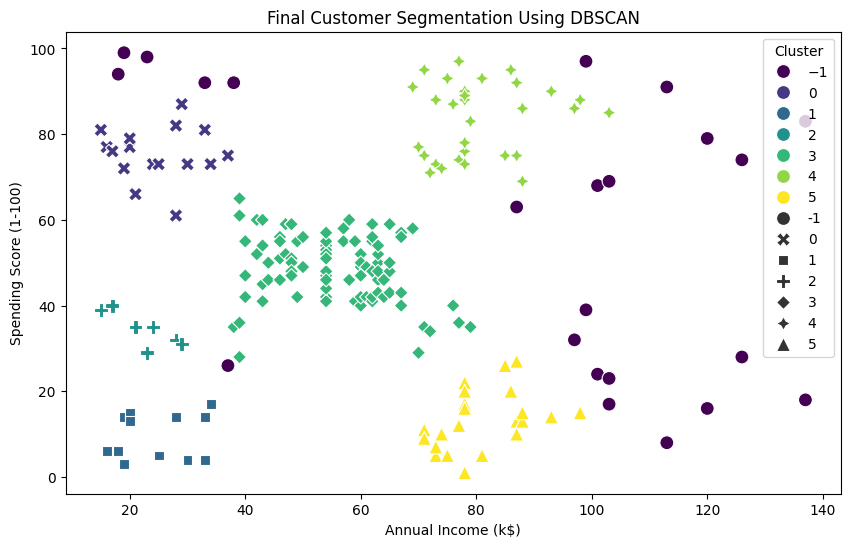

In [ ]:
# Calculate mean statistics for each cluster
cluster_stats = clustered_df.groupby("Cluster").agg({
    "Annual Income (k$)": ["mean", "min", "max"],
    "Spending Score (1-100)": ["mean", "min", "max"],
    "CustomerID": "count"
})

cluster_stats = cluster_stats.rename(
    columns={"CustomerID": "Customer Count"}
)

print("Cluster Statistics:")
print(cluster_stats)

# Display noise points separately
noise_points = clustered_df[clustered_df["Cluster"] == -1]

print("\nNumber of noise points:", len(noise_points))
print("\nNoise point details:")
print(noise_points.head(10))

# Visualize cluster statistics
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clustered_df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    style="Cluster",
    s=100
)

plt.title("Final Customer Segmentation Using DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.